In [615]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [616]:
df = pd.read_csv(r"C:\Users\HP\Desktop/Ironhack/WK5/Day-1/amz_uk_price_prediction_dataset.csv")
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [617]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

In [618]:
# Retrieving the unique data types present in the dataframe columns
list(set(df.dtypes.tolist()))

[dtype('int64'), dtype('float64'), dtype('O'), dtype('bool')]

In [619]:
# Extracting column names with numerical data types from the dataframe
df.select_dtypes("number").columns

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

In [620]:
# Counting and sorting the unique values for each numerical column in descending order
df.select_dtypes("number").nunique().sort_values(ascending=False)

uid                  2443651
price                  82916
reviews                19446
stars                     42
boughtInLastMonth         25
dtype: int64

In [621]:
df["stars"].unique()

array([4.7, 4.6, 4.5, 4.8, 0. , 4.4, 4.3, 4.1, 4.9, 5. , 3.8, 3.6, 4. ,
       4.2, 3. , 3.9, 2.5, 3.4, 3.7, 3.2, 3.3, 3.5, 2.7, 2.1, 1. , 3.1,
       2. , 2.9, 2.8, 1.5, 2.2, 2.3, 2.6, 2.4, 1.4, 1.9, 1.8, 1.7, 1.6,
       1.2, 1.3, 1.1])

In [622]:
# Retrieving column names with object (typically string) data types from the dataframe
df.select_dtypes("object").columns

Index(['asin', 'title', 'category'], dtype='object')

In [623]:
df.select_dtypes("object").nunique().sort_values(ascending=False)

asin        2222742
title       2077591
category        296
dtype: int64

In [624]:
# Getting the numerical and categorical columns
df_numerical = df[df.select_dtypes("number").columns]
df_categorical = df[df.select_dtypes("object").columns]

In [625]:
## PART ONE

In [626]:
##Frequency tables

In [627]:
# Generate a frequency table for the product category
##Calculating the frequency table
frequency_table = df_categorical['category'].value_counts()

# Calculating the proportion of each unique value in the 'MSZoning'
proportion_table = df_categorical['category'].value_counts(normalize=True)

frequency_table, proportion_table




(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
                                            ...  
 Alexa Built-In Devices                       107
 Motorbike Chassis                            107
 Plugs                                        107
 Smart Home Security & Lighting               104
 Smart Speakers                                54
 Name: count, Length: 296, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
                                             ...   
 Alexa Built-In Devices                    0.000044
 Motorbike Chassis       

In [628]:
##Top 5 most listed category
Top_5 = df_categorical['category'].value_counts().head(5)
Top_5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

C:\Users\HP\AppData\Local\Temp\ipykernel_9192\2214212049.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=Top_5.index, y=Top_5.values, palette="Set3")
C:\Users\HP\AppData\Local\Temp\ipykernel_9192\2214212049.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')


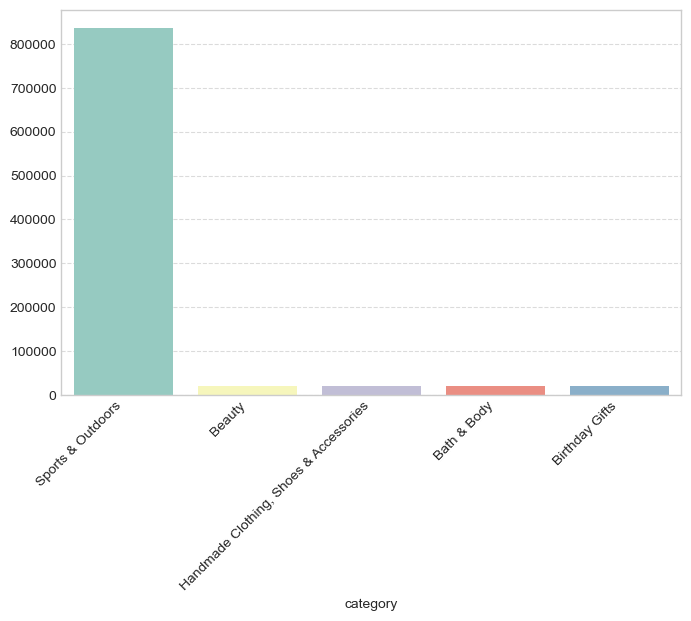

In [629]:
## Visualizations:
## Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.

plt.figure(figsize=(8, 5))
ax = plt.gca()
sns.barplot(x=Top_5.index, y=Top_5.values, palette="Set3")
plt.grid(axis='y', linestyle='--', alpha=0.7)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha='right')
plt.show()

In [630]:
Top_prop = df_categorical['category'].value_counts(normalize=True).head(5)
Top_prop

category
Sports & Outdoors                         0.342219
Beauty                                    0.007903
Handmade Clothing, Shoes & Accessories    0.007869
Bath & Body                               0.007813
Birthday Gifts                            0.007766
Name: proportion, dtype: float64

In [631]:
cc=pd.DataFrame(Top_prop).reset_index()
cc

,category,proportion
0,Sports & Outdoors,0.342219
1,Beauty,0.007903
2,"Handmade Clothing, Shoes & Accessories",0.007869
3,Bath & Body,0.007813
4,Birthday Gifts,0.007766


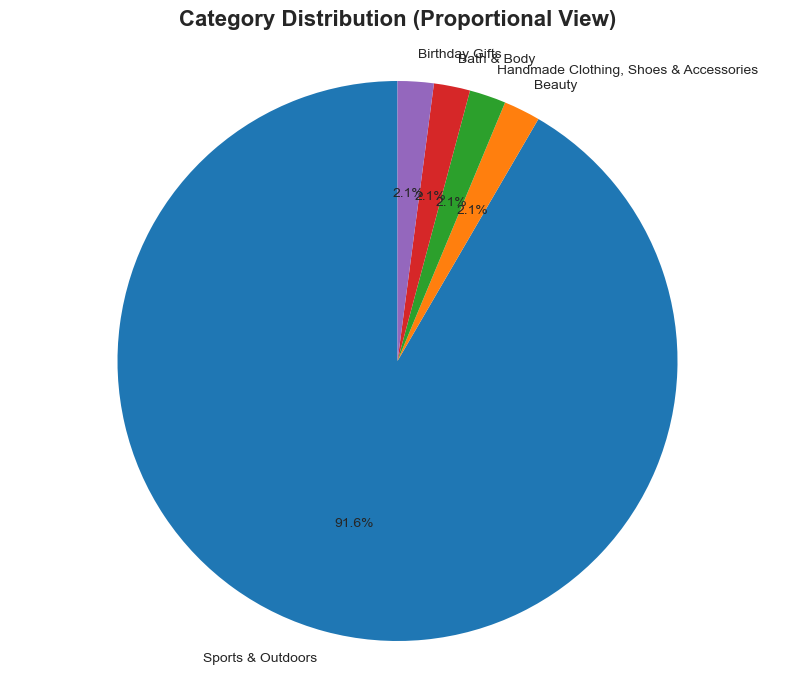

In [632]:
## For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
#Prepare Data for Plotting ---
labels = cc['category']
sizes = cc['proportion']

plt.figure(figsize=(10, 8))


plt.pie(
    sizes, 
    labels=labels, 
    autopct='%1.1f%%',       # Format percentages to show one decimal place
    startangle=90,           # Start the first slice at the top
)

plt.title("Category Distribution (Proportional View)", fontsize=16, fontweight='bold', pad=20)

# Ensure the pie chart is drawn as a circle (equal aspect ratio)
plt.axis('equal') 

plt.show()

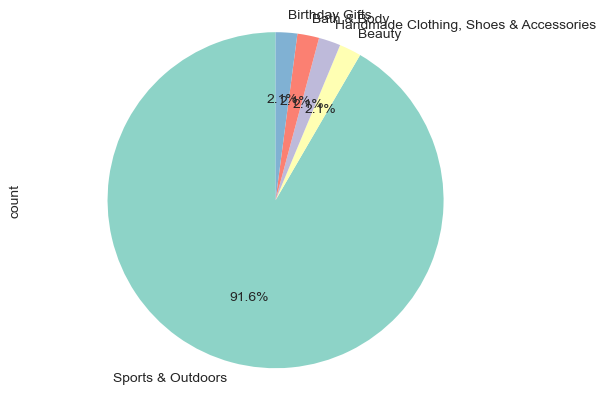

In [633]:
df_categorical['category'].value_counts().head(5).plot.pie(autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))
plt.axis('equal') 
plt.show()

## Clearly the Sports & Outdoors category dominates the listings.

In [634]:
### PART TWO

In [635]:
## Measures of Centrality:
## Calculate the mean, median, and mode for the price of products.
mean_=round(df_numerical["price"].mean(),1)
median_=df_numerical["price"].median()
mode_=df_numerical["price"].mode()[0]
mean_, median_, mode_

(89.2, 19.09, 9.99)

In [636]:
## The average price point of all products is 89.2 euros while the most occuring price is 9.99 euros. The mean is far greater than the mode indicating that---
##--- a large cluster of products are sold in the modal price with some very high value product as outliers making the mean value go high.


In [637]:
## Measures of Dispersion:
## Determine the variance, standard deviation, range, and interquartile range for product price.
variance_price = round(df_numerical['price'].var(),1)
std_dev_price = round(df_numerical['price'].std(),1)
min_price = df_numerical['price'].min()
max_price = df_numerical['price'].max()
range_price = max_price - min_price
quantiles_price = df_numerical['price'].quantile([0.25, 0.75])
interquartile_range=list(quantiles_price)

variance_price, std_dev_price, min_price, max_price, range_price,interquartile_range

(119445.5, 345.6, 0.0, 100000.0, 100000.0, [9.99, 45.99])

In [638]:
## How varied are the product prices? Are there any indicators of a significant spread in prices?
## ANSWER: The prices really varies widely from one another due to the high Standard deviation,variance and range values

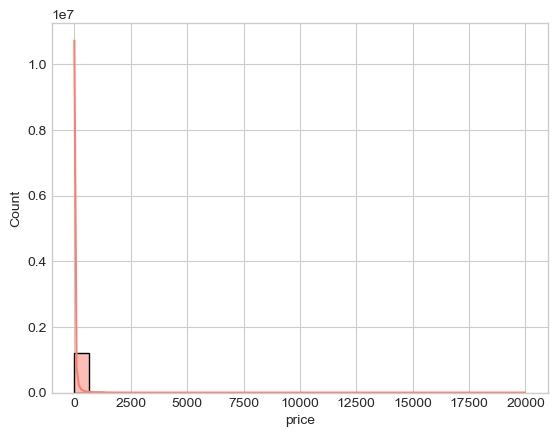

In [660]:
## Visualizations:

##Is there a specific price range where most products fall?
##ANSWER: Most product fall in the price range of 9.99 euros
sns.histplot(df_numerical['price'], kde=True, bins=30, color="salmon")
plt.show()

In [656]:
## Due to the heavy skewness of the chart, it's recommended to use a Log transform before visualizing with Histogram'
df_log=df_numerical.copy()
df_log
df_log['price']=np.log1p(df_log['price'])

,uid,stars,reviews,price,boughtInLastMonth
0,1,4.7,15308,21.99,0
1,2,4.7,98099,23.99,0
2,3,4.7,15308,21.99,0
3,4,4.7,7205,31.99,0
4,5,4.6,1881,17.99,0
...,...,...,...,...,...
2443642,2828585,3.6,66,49.99,0
2443643,2828586,4.1,5,158.99,0
2443644,2828587,3.6,12,14.99,0
2443649,2828592,4.3,404,79.99,0


In [657]:

df_log['price']=np.log1p(df_log['price'])

C:\Users\HP\AppData\Local\Temp\ipykernel_9192\2367712779.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


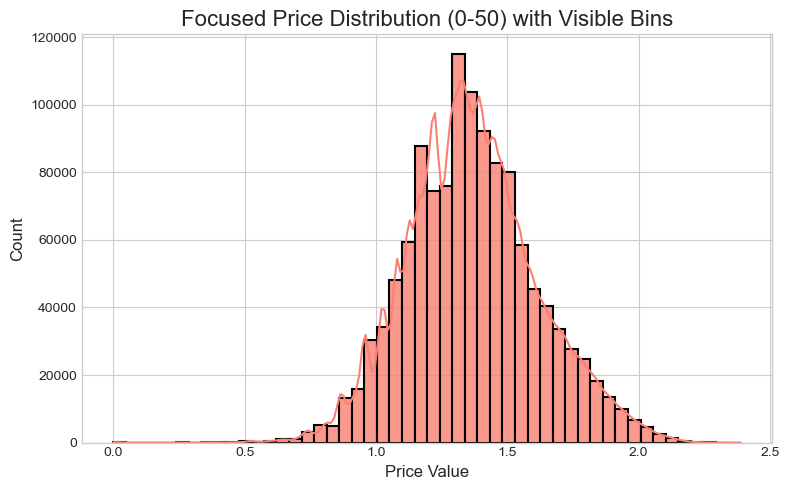

In [658]:
df_log['price']=np.log1p(df_log['price'])
plt.figure(figsize=(8, 5))
ax = plt.gca()
sns.histplot(
    df_log['price'], 
    kde=True, 
    bins=50, 
    color="salmon",
    edgecolor='black',       # Makes the outline of each bar visible
    linewidth=1.5,           # Thickness of the bar outline
    stat='count',            # Ensure y-axis shows raw counts
    alpha=0.8,               # Slightly lower alpha to distinguish fill from edge
    ax=ax
    
)
ax.legend()

ax.set_title('Focused Price Distribution (0-50) with Visible Bins', fontsize=16)
ax.set_xlabel('Price Value', fontsize=12)
ax.set_ylabel('Count', fontsize=12)

plt.tight_layout()
plt.show()

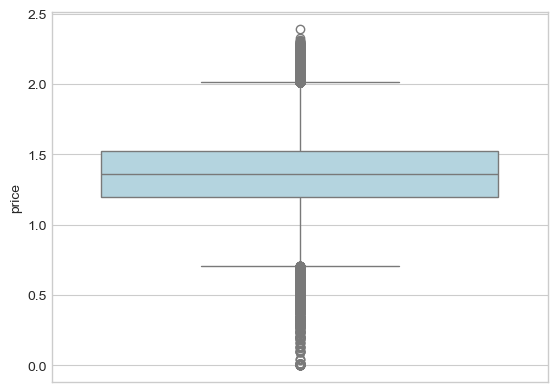

In [661]:
##
sns.boxplot(data = df_log['price'], color="lightblue")
plt.show()

## There are some products with extremely high prices compared to others and these prices are outliers in the price column.

In [644]:
## Part 3: Unpacking Product Ratings



In [645]:
## There is a common trade of customers rating products as zero

In [646]:
#Remove all entries of 0.0 in the stars column
df_numerical = df_numerical[df_numerical["stars"] > 0.0].copy()

In [647]:
df_numerical["stars"].unique()

array([4.7, 4.6, 4.5, 4.8, 4.4, 4.3, 4.1, 4.9, 5. , 3.8, 3.6, 4. , 4.2,
       3. , 3.9, 2.5, 3.4, 3.7, 3.2, 3.3, 3.5, 2.7, 2.1, 1. , 3.1, 2. ,
       2.9, 2.8, 1.5, 2.2, 2.3, 2.6, 2.4, 1.4, 1.9, 1.8, 1.7, 1.6, 1.2,
       1.3, 1.1])

In [648]:
## Measures of Centrality:
## Calculate the mean, median, and mode for the rating of products.
mean_=round(df_numerical["stars"].mean(),1)
median_=df_numerical["stars"].median()
mode_=df_numerical["stars"].mode()[0]
mean_, median_, mode_

#Customers generally rate products very high with a minimum of 4.3 star rating.

(4.3, 4.4, 4.5)

In [649]:
## df_numerical.loc[df_numerical['stars']==0, 'stars'] = 2

In [650]:
## Measures of Dispersion:
## Determine the variance, standard deviation, and interquartile range for product rating.
variance_price = round(df_numerical["stars"].var(),1)
std_dev_price = round(df_numerical["stars"].std(),1)
min_price = df_numerical["stars"].min()
max_price = df_numerical["stars"].max()
range_price = max_price - min_price
quantiles_price = df_numerical["stars"].quantile([0.25, 0.75])
interquartile_range=list(quantiles_price)

variance_price, std_dev_price, min_price, max_price, range_price,interquartile_range


(0.3, 0.6, 1.0, 5.0, 4.0, [4.1, 4.6])

In [651]:
## Are the ratings consistent, or is there a wide variation in customer feedback?
## ANSWER: The rating are very consistent with very low variation as seen from the low standard deviation and variance values.

In [652]:
## Shape of the Distribution:
## Calculate the skewness and kurtosis for the rating column.
skewness_price = df_numerical["stars"].skew()
kurtosis_price = df_numerical["stars"].kurtosis()

skewness_price, kurtosis_price

(-2.3795681122127945, 9.78193769066435)

In [653]:
# The rating column is not normally distributed. From the negative skewness, the stars column has a longer left tail indicating that there are lower ratings--- 
#--acting as outliers pulling the mean lower.
# The positive kurtosis value indicates that there are more extreme values of outliers than the normal distribution.

In [654]:
# Visualizations:
# Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?
## 4.5 rating is more common as seen from the Histogram plot.

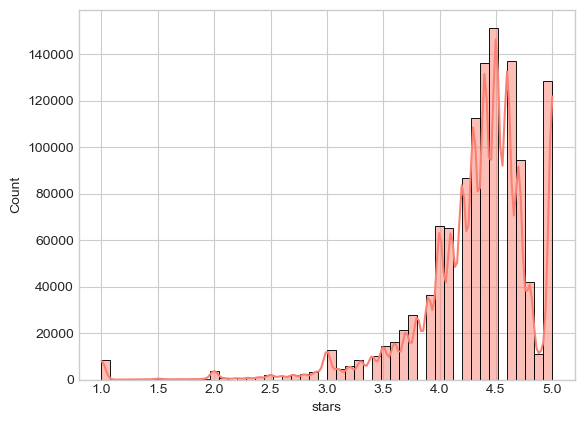

In [655]:
sns.histplot(df_numerical['stars'], kde=True, bins=50, color="salmon")
plt.show()